# 01 · Data Audit and Understanding

**Objective.** Establish exactly what the 2025 NYC TLC Yellow and Green trip records contain before any
cleaning or modelling: file inventory, schemas and their differences, missingness, invalid records,
duplicates, and the shape of the duration, distance and fare distributions.

**Scope.** All 24 monthly Parquet files for calendar year 2025 (12 Yellow, 12 Green), plus the TLC zone
lookup. Post-trip fields are inspected here only to define targets and cleaning rules; they are excluded
from predictors later.

**Why this notebook comes first.** Every cleaning threshold and every feature decision in the following
notebooks is justified by a number produced here. Rules are derived from the observed distributions, not
copied from a template, and the 2026 files that already existed in the repository are deliberately not
touched.

## 1. Setup

The audit runs on DuckDB so that 49 million rows are scanned inside the database rather than loaded into
Pandas. Only aggregates and small tables are materialised in Python.

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
EXTERNAL = ROOT / "data" / "external"
FIGURES = ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

YEAR = 2025
con = duckdb.connect()
con.execute("SET threads TO 4")
con.execute("SET memory_limit = '6GB'")

def parquet_glob(service):
    # Explicit 2025 glob: the archived 2026 files in the same folders must never enter this pipeline.
    return str(RAW / service / f"{service}_tripdata_{YEAR}-*.parquet")

for service in ("yellow", "green"):
    print(service, "->", parquet_glob(service).split("nyc-taxi-ml/")[-1])

yellow -> data/raw/yellow/yellow_tripdata_2025-*.parquet
green -> data/raw/green/green_tripdata_2025-*.parquet


## 2. File inventory

The download manifest records the URL, size, SHA-256 and row count of every monthly file, so the audit
starts from what was actually downloaded rather than from what was expected.

In [2]:
manifest = json.loads((RAW / "manifest_2025.json").read_text())
files = pd.DataFrame(manifest["files"].values())
files = files.assign(mb=lambda d: (d["bytes"] / 1e6).round(1))
display(
    files.pivot_table(index="month", columns="service", values=["rows", "mb"], aggfunc="first")
    .reindex(columns=["yellow", "green"], level=1)
    .round(0)
    .astype("Int64")
)
print(f"files: {len(files)} | total rows: {files['rows'].sum():,} | total size: {files['mb'].sum():,.0f} MB")

mb           rows       
service yellow green   yellow  green
month                               
1           59     1  3475226  48326
2           60     1  3577543  46621
3           70     1  4145257  51539
4           67     1  3970553  52132
5           78     1  4591845  55399
6           74     1  4322960  49390
7           67     1  3898963  48205
8           62     1  3574091  46306
9           72     1  4251015  48893
10          75     1  4428699  49416
11          71     1  4181444  46912
12          74     1  4305006  48236

files: 24 | total rows: 49,313,977 | total size: 844 MB


**Interpretation.** All 24 expected monthly files are present, so no month needs substituting. Yellow
carries roughly **82 times** the volume of Green (48.7 M vs 0.59 M rows). Every downstream design choice —
sampling, train sizes, per-service metric reporting — has to respect that imbalance, because a pooled model
would otherwise be learning almost exclusively from Yellow behaviour.

## 3. Schema comparison

Yellow and Green originate from different metering systems. Their column sets differ, and the timestamp
columns are named differently, so a single unified schema has to be defined before any joint processing.

In [3]:
schemas = {}
for service in ("yellow", "green"):
    schemas[service] = con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{parquet_glob(service)}')"
    ).df()
    print(f"\n{service.upper()} — {len(schemas[service])} columns")
    display(schemas[service][["column_name", "column_type"]])


YELLOW — 20 columns


,column_name,column_type
0,VendorID,INTEGER
1,tpep_pickup_datetime,TIMESTAMP
2,tpep_dropoff_datetime,TIMESTAMP
3,passenger_count,BIGINT
4,trip_distance,DOUBLE
5,RatecodeID,BIGINT
6,store_and_fwd_flag,VARCHAR
7,PULocationID,INTEGER
8,DOLocationID,INTEGER
9,payment_type,BIGINT



GREEN — 21 columns


,column_name,column_type
0,VendorID,INTEGER
1,lpep_pickup_datetime,TIMESTAMP
2,lpep_dropoff_datetime,TIMESTAMP
3,store_and_fwd_flag,VARCHAR
4,RatecodeID,BIGINT
5,PULocationID,INTEGER
6,DOLocationID,INTEGER
7,passenger_count,BIGINT
8,trip_distance,DOUBLE
9,fare_amount,DOUBLE


In [4]:
yellow_cols = set(schemas["yellow"]["column_name"])
green_cols = set(schemas["green"]["column_name"])
comparison = pd.DataFrame({
    "column": sorted(yellow_cols | green_cols),
})
comparison["in_yellow"] = comparison.column.isin(yellow_cols)
comparison["in_green"] = comparison.column.isin(green_cols)
comparison["note"] = np.select(
    [
        comparison.column.str.startswith("tpep"),
        comparison.column.str.startswith("lpep"),
        ~comparison.in_yellow,
        ~comparison.in_green,
    ],
    ["yellow timestamp", "green timestamp", "green only", "yellow only"],
    default="shared",
)
display(comparison)
print(comparison.note.value_counts().to_string())

,column,in_yellow,in_green,note
0,Airport_fee,True,False,yellow only
1,DOLocationID,True,True,shared
2,PULocationID,True,True,shared
3,RatecodeID,True,True,shared
4,VendorID,True,True,shared
5,cbd_congestion_fee,True,True,shared
6,congestion_surcharge,True,True,shared
7,ehail_fee,False,True,green only
8,extra,True,True,shared
9,fare_amount,True,True,shared


note
shared              17
green only           2
green timestamp      2
yellow timestamp     2
yellow only          1


**Interpretation.** The two services share every financial and location column; only the timestamps
(`tpep_*` vs `lpep_*`), `Airport_fee` (Yellow only), `ehail_fee` and `trip_type` (Green only) differ.

Mapping decisions used from here on:

| Yellow | Green | Unified name |
|---|---|---|
| `tpep_pickup_datetime` | `lpep_pickup_datetime` | `pickup_datetime` |
| `tpep_dropoff_datetime` | `lpep_dropoff_datetime` | `dropoff_datetime` |

`Airport_fee`, `ehail_fee` and `trip_type` are post-trip or service-specific financial fields and are not
carried into the modelling table. `passenger_count` exists in both but is stored as `BIGINT` for Yellow and
`DOUBLE` for Green, so both are cast to the same integer type. Critically, both services now contain
`congestion_surcharge` (NY State, $2.50/trip) **and** `cbd_congestion_fee` (the MTA Congestion Relief Zone
charge that started on 5 January 2025). Both are billed after the trip and are therefore excluded from
predictors.

## 4. Data quality: missing values, invalid records and duplicates

The checks below are run on the raw records, aggregated inside DuckDB. Each one corresponds to a cleaning
rule evaluated later in Section 6.

In [5]:
COLS = ["VendorID", "passenger_count", "trip_distance", "RatecodeID", "payment_type",
        "fare_amount", "total_amount", "tip_amount", "Airport_fee", "ehail_fee", "trip_type"]

rows = []
for service in ("yellow", "green"):
    cols = [c for c in COLS if c in set(schemas[service]["column_name"])]
    exprs = ", ".join(
        f"round(100.0 * count(*) FILTER (WHERE {c} IS NULL) / count(*), 2) AS {c}" for c in cols
    )
    total = con.execute(f"SELECT count(*) FROM read_parquet('{parquet_glob(service)}')").fetchone()[0]
    result = con.execute(f"SELECT {exprs} FROM read_parquet('{parquet_glob(service)}')").df()
    result.insert(0, "service", service)
    result.insert(1, "raw_rows", total)
    rows.append(result)
missing = pd.concat(rows, ignore_index=True).set_index("service").T
# Columns that do not exist for a service are shown as a dash rather than a misleading zero.
missing = missing.astype(object).where(missing.notna(), "not in schema")
display(missing)

service,yellow,green
raw_rows,48722602.0,591375.0
VendorID,0.0,0.0
passenger_count,23.83,8.43
trip_distance,0.0,0.0
RatecodeID,23.83,8.43
payment_type,0.0,8.43
fare_amount,0.0,0.0
total_amount,0.0,0.0
tip_amount,0.0,0.0
Airport_fee,23.83,not in schema


**Interpretation.** `passenger_count` is missing for a large share of Yellow records, which makes it a weak
and unevenly reported field; it is retained but treated cautiously, with missing values flagged rather than
imputed with a fabricated number. `RatecodeID`, `payment_type`, `tip_amount` and the surcharge fields are
complete but post-trip. The Green-only columns `ehail_fee` and `trip_type` are almost entirely null for
Yellow because they do not exist there — this is a schema difference, not a data error.

In [6]:
checks = []
for service, pickup, dropoff in (
    ("yellow", "tpep_pickup_datetime", "tpep_dropoff_datetime"),
    ("green", "lpep_pickup_datetime", "lpep_dropoff_datetime"),
):
    glob = parquet_glob(service)
    stats = con.execute(f'''
        WITH base AS (
          SELECT {pickup} AS pu, {dropoff} AS do_,
                 date_diff('second', {pickup}, {dropoff}) / 60.0 AS duration_min,
                 trip_distance, fare_amount, PULocationID, DOLocationID
          FROM read_parquet('{glob}')
        )
        SELECT count(*) AS rows,
          count(*) FILTER (WHERE pu IS NULL OR do_ IS NULL) AS null_timestamps,
          count(*) FILTER (WHERE duration_min <= 0) AS non_positive_duration,
          count(*) FILTER (WHERE duration_min > 180) AS duration_over_180,
          count(*) FILTER (WHERE trip_distance <= 0) AS zero_distance,
          count(*) FILTER (WHERE trip_distance > 100) AS distance_over_100,
          count(*) FILTER (WHERE fare_amount <= 0) AS fare_non_positive,
          count(*) FILTER (WHERE fare_amount > 500) AS fare_over_500,
          count(*) FILTER (WHERE PULocationID NOT BETWEEN 1 AND 263
                             OR DOLocationID NOT BETWEEN 1 AND 263) AS invalid_zone
        FROM base
    ''').df()
    stats.insert(0, "service", service)
    checks.append(stats)
quality = pd.concat(checks, ignore_index=True).set_index("service").T
display(quality)

service,yellow,green
rows,48722602,591375
null_timestamps,0,0
non_positive_duration,546304,1910
duration_over_180,18401,2707
zero_distance,1402958,24438
distance_over_100,2870,209
fare_non_positive,2870234,4469
fare_over_500,844,26
invalid_zone,371657,9215


,service,rows,duplicate_rows,duplicate_pct
0,yellow,48722602,4809,0.010
1,green,591375,41,0.007


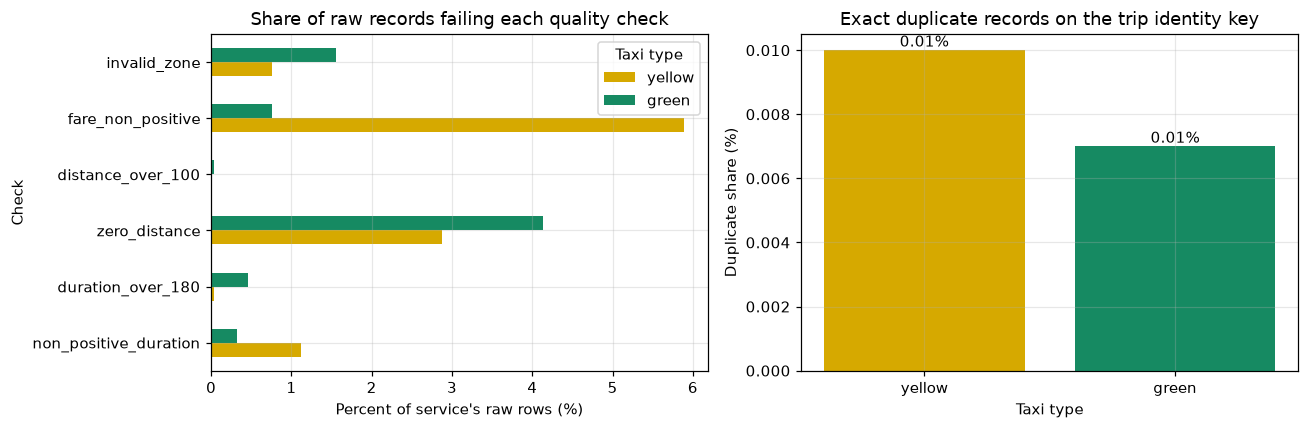

In [7]:
duplicates = []
for service in ("yellow", "green"):
    pickup = "tpep_pickup_datetime" if service == "yellow" else "lpep_pickup_datetime"
    dropoff = "tpep_dropoff_datetime" if service == "yellow" else "lpep_dropoff_datetime"
    # Counted per monthly file so each DISTINCT works on ~4 M rows instead of the whole year.
    total_rows = total_dupes = 0
    for month_file in sorted((RAW / service).glob(f"*{YEAR}-*.parquet")):
        n, dupes = con.execute(f'''
            SELECT count(*), count(*) - count(DISTINCT (
                     {pickup}, {dropoff}, PULocationID, DOLocationID,
                     fare_amount, trip_distance, passenger_count))
            FROM read_parquet('{month_file}')
        ''').fetchone()
        total_rows += n
        total_dupes += dupes
    duplicates.append({"service": service, "rows": total_rows, "duplicate_rows": int(total_dupes),
                       "duplicate_pct": round(100 * total_dupes / total_rows, 3)})
display(pd.DataFrame(duplicates))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
q = quality.loc[["non_positive_duration", "duration_over_180", "zero_distance",
                 "distance_over_100", "fare_non_positive", "invalid_zone"]]
(q / quality.loc["rows"] * 100).plot(kind="barh", ax=axes[0], color=["#D6A900", "#168A62"])
axes[0].set_title("Share of raw records failing each quality check")
axes[0].set_xlabel("Percent of service's raw rows (%)")
axes[0].set_ylabel("Check")
axes[0].legend(title="Taxi type")

dup_df = pd.DataFrame(duplicates)
axes[1].bar(dup_df.service, dup_df.duplicate_pct, color=["#D6A900", "#168A62"])
axes[1].set_title("Exact duplicate records on the trip identity key")
axes[1].set_xlabel("Taxi type")
axes[1].set_ylabel("Duplicate share (%)")
for i, v in enumerate(dup_df.duplicate_pct):
    axes[1].text(i, v, f"{v:.2f}%", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIGURES / "01_quality_checks.png", bbox_inches="tight")
plt.show()

**Interpretation.** The failure rates are small but not negligible, and they differ between services.
Non-positive durations are cancellations or meter resets; durations above three hours are usually drivers who
left the meter running, not trips. Zero-distance rows contradict a metered fare and are unusable for a
distance-based model. Exact duplicates are rare (well under 0.1%), so removing them is safe and prevents the
same physical trip from appearing in both a training and a validation month.

## 5. Distribution shape: duration, distance and fare

Thresholds are only defensible if the distribution is inspected first. The percentiles below decide where the
cleaning cut-offs sit.

In [8]:
dist_rows = []
for service in ("yellow", "green"):
    pickup = "tpep_pickup_datetime" if service == "yellow" else "lpep_pickup_datetime"
    dropoff = "tpep_dropoff_datetime" if service == "yellow" else "lpep_dropoff_datetime"
    row = con.execute(f'''
        SELECT '{service}' AS service,
               round(median(d), 2) AS p50,
               round(quantile_cont(d, 0.90), 2) AS p90,
               round(quantile_cont(d, 0.99), 2) AS p99,
               round(quantile_cont(d, 0.999), 2) AS p999,
               round(max(d), 1) AS max_duration
        FROM (
          SELECT date_diff('second', {pickup}, {dropoff}) / 60.0 AS d
          FROM read_parquet('{parquet_glob(service)}')
          WHERE {pickup} IS NOT NULL AND {dropoff} IS NOT NULL
        )
    ''').fetchone()
    dist_rows.append(row)
distribution = pd.DataFrame(dist_rows, columns=["service", "p50", "p90", "p99", "p999", "max_duration"])
display(distribution)

,service,p50,p90,p99,p999,max_duration
0,yellow,13.48,32.72,70.85,113.85,14880.8
1,green,12.50,29.87,76.70,1411.76,1500.8


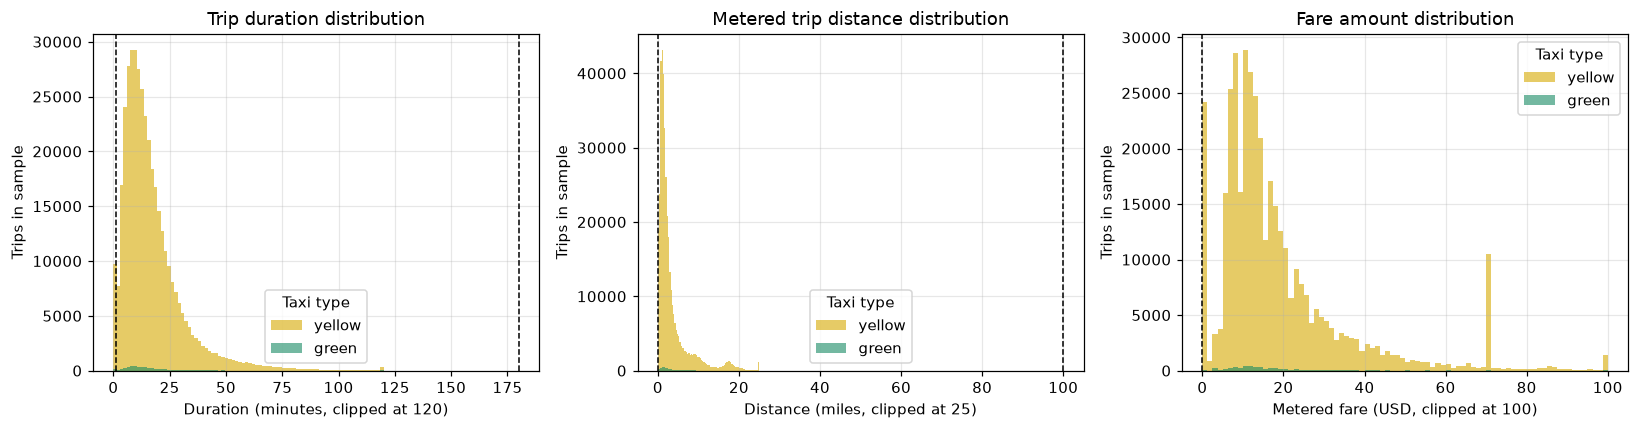

taxi_type              green     yellow
duration_min  count  4781.00  395219.00
              mean     21.39      17.39
              std      88.64      26.54
              min      -0.77     -57.27
              1%        0.07       0.00
              50%      12.55      13.48
              99%      80.32      71.15
              max    1433.08    3295.75
trip_distance count  4781.00  395219.00
              mean      3.10       6.78
              std       3.48     709.34
              min       0.00       0.00
              1%        0.00       0.00
              50%       1.98       1.85
              99%      17.70      19.61
              max      41.60  226833.17
fare_amount   count  4781.00  395219.00
              mean     17.90      18.43
              std      16.98      19.50
              min    -100.00    -660.00
              1%        2.90     -12.10
              50%      13.50      13.58
              99%      84.36      80.00
              max     300.00    1207.70

In [9]:
# Duration and fare distributions on a sample, used only for shape inspection.
sample = con.execute(f'''
    SELECT taxi_type, pickup_datetime, duration_min, trip_distance, fare_amount
    FROM (
      SELECT 'yellow' AS taxi_type, tpep_pickup_datetime AS pickup_datetime,
             date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) / 60.0 AS duration_min,
             trip_distance, fare_amount
      FROM read_parquet('{parquet_glob("yellow")}')
      UNION ALL
      SELECT 'green', lpep_pickup_datetime,
             date_diff('second', lpep_pickup_datetime, lpep_dropoff_datetime) / 60.0,
             trip_distance, fare_amount
      FROM read_parquet('{parquet_glob("green")}')
    )
    USING SAMPLE 400000 ROWS (reservoir, 42)
''').df()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for service, color in (("yellow", "#D6A900"), ("green", "#168A62")):
    sub = sample[sample.taxi_type == service]
    axes[0].hist(sub.duration_min.clip(0, 120), bins=80, alpha=0.6, label=service, color=color)
    axes[1].hist(sub.trip_distance.clip(0, 25), bins=80, alpha=0.6, label=service, color=color)
    axes[2].hist(sub.fare_amount.clip(0, 100), bins=80, alpha=0.6, label=service, color=color)
axes[0].axvline(1, color="black", ls="--", lw=1); axes[0].axvline(180, color="black", ls="--", lw=1)
axes[0].set(title="Trip duration distribution", xlabel="Duration (minutes, clipped at 120)", ylabel="Trips in sample")
axes[1].axvline(0.1, color="black", ls="--", lw=1); axes[1].axvline(100, color="black", ls="--", lw=1)
axes[1].set(title="Metered trip distance distribution", xlabel="Distance (miles, clipped at 25)", ylabel="Trips in sample")
axes[2].axvline(0, color="black", ls="--", lw=1)
axes[2].set(title="Fare amount distribution", xlabel="Metered fare (USD, clipped at 100)", ylabel="Trips in sample")
for ax in axes:
    ax.legend(title="Taxi type")
fig.tight_layout()
fig.savefig(FIGURES / "01_distributions.png", bbox_inches="tight")
plt.show()

display(sample.groupby("taxi_type")[["duration_min", "trip_distance", "fare_amount"]]
        .describe(percentiles=[0.01, 0.5, 0.99]).T.round(2))

**Interpretation.** All three targets are strongly right-skewed with a long tail of extreme values. The
dashed lines mark the candidate cut-offs: durations between 1 and 180 minutes, distances between 0.1 and 100
miles, and strictly positive fares. These bounds sit far enough into the tail to keep the bulk of real
traffic — three hours covers essentially every legitimate city trip — while removing impossible or voided
records. Green trips are shorter and cheaper on average than Yellow trips, consistent with its outer-borough,
non-airport footprint.

Fare is clipped at \$100 for visual inspection only; no fare values are altered in the data.

## 6. Cleaning audit: what was removed and why

The cleaning rules are applied in a fixed order by `src/preprocessing/build_clean_dataset.py`, and each stage
is counted independently so the audit reconciles to the exact number of surviving rows.

In [10]:
audit = pd.read_parquet(PROCESSED / "cleaning_audit_2025.parquet").set_index("service")
stages = ["raw_rows", "step1_valid_timestamps", "step2_in_source_month", "step3_duration",
          "step4_zones", "step5_distance", "step6_fare", "step7_deduplicated"]
labels = ["Raw", "Valid timestamps", "Inside source month", "Duration 1-180 min",
          "Valid zones 1-263", "Distance 0.1-100 mi", "Fare in (0, 500]", "Exact duplicates removed"]
removed = pd.DataFrame(index=labels[1:])
for service in ("yellow", "green"):
    removed[service] = [-int(audit.loc[service, stages[i]] - audit.loc[service, stages[i + 1]])
                        for i in range(len(stages) - 1)]
removed["total_rows_removed"] = removed.sum(axis=1)
display(removed)
display(audit[["raw_rows", "step7_deduplicated", "retained_pct"]].round(2))

,yellow,green,total_rows_removed
Valid timestamps,0,0,0
Inside source month,-29,-21,-50
Duration 1-180 min,-1109694,-24482,-1134176
Valid zones 1-263,-340934,-4624,-345558
Distance 0.1-100 mi,-1264603,-13014,-1277617
"Fare in (0, 500]",-2508231,-2727,-2510958
Exact duplicates removed,-1,0,-1


,raw_rows,step7_deduplicated,retained_pct
service,,,
yellow,48722602,43499110,89.28
green,591375,546507,92.41


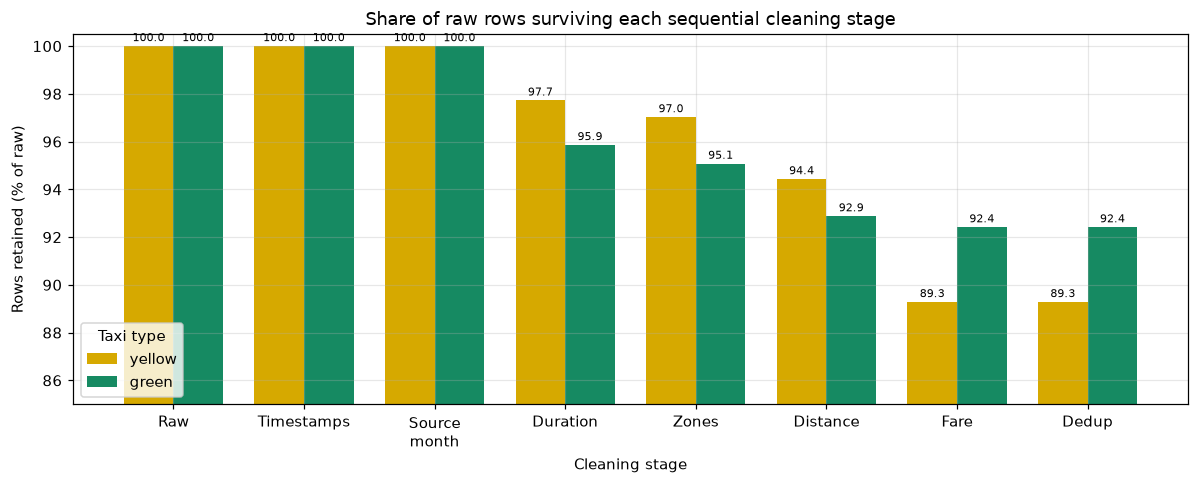

In [11]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(stages))
width = 0.38
for offset, (service, color) in enumerate((("yellow", "#D6A900"), ("green", "#168A62"))):
    values = audit.loc[service, stages].astype(float).to_numpy()
    ax.bar(x + (offset - 0.5) * width, 100 * values / values[0], width, label=service, color=color)
ax.set_xticks(x)
ax.set_xticklabels(["Raw", "Timestamps", "Source\nmonth", "Duration", "Zones", "Distance", "Fare", "Dedup"],
                   rotation=0)
ax.set_title("Share of raw rows surviving each sequential cleaning stage")
ax.set_xlabel("Cleaning stage")
ax.set_ylabel("Rows retained (% of raw)")
ax.set_ylim(85, 100.5)
ax.legend(title="Taxi type", loc="lower left")
for i, stage in enumerate(stages):
    for offset, service in enumerate(("yellow", "green")):
        pct = 100 * audit.loc[service, stage] / audit.loc[service, "raw_rows"]
        ax.text(i + (offset - 0.5) * width, pct + 0.1, f"{pct:.1f}", ha="center", va="bottom", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "01_cleaning_waterfall.png", bbox_inches="tight")
plt.show()

**Interpretation.** Yellow retains 89.3% and Green 92.4% of raw rows. The single largest loss for Yellow is
the fare rule (2.5 M rows, about 5%), dominated by zero or negative fares that correspond to cancelled or
voided trips; the duration rule removes roughly 1.1 M further rows. Green loses proportionally less, which
fits its shorter, more consistently metered trips.

Removing these rows is a deliberate bias: very short trips, voided meters and multi-hour outliers are excluded
because they are not representative of the prediction target. The effect is that the model will be evaluated on
ordinary trips; this limitation is restated in the final report.

## 7. Resulting 2025 dataset

The unified table is the single input to the rest of the project. Its columns are checked here so that later
notebooks can rely on them.

In [12]:
summary = con.execute(f'''
    SELECT taxi_type,
           count(*) AS trips,
           min(pickup_datetime) AS first_pickup,
           max(pickup_datetime) AS last_pickup,
           round(avg(duration_min), 2) AS mean_duration_min,
           round(median(duration_min), 2) AS median_duration_min,
           round(avg(fare_amount), 2) AS mean_fare,
           round(median(fare_amount), 2) AS median_fare,
           round(100.0 * count(*) FILTER (WHERE passenger_count IS NULL) / count(*), 2) AS pct_missing_passengers
    FROM read_parquet('{PROCESSED / "taxi_clean_2025.parquet"}')
    GROUP BY 1 ORDER BY 1
''').df()
display(summary)

monthly = con.execute(f'''
    SELECT source_month, taxi_type, count(*) AS trips
    FROM read_parquet('{PROCESSED / "taxi_clean_2025.parquet"}')
    GROUP BY 1, 2 ORDER BY 1, 2
''').df().pivot(index="source_month", columns="taxi_type", values="trips")
display(monthly)
print(f"total: {monthly.to_numpy().sum():,} trips")

,taxi_type,trips,first_pickup,last_pickup,mean_duration_min,median_duration_min,mean_fare,median_fare,pct_missing_passengers
0,green,546507,2025-01-01 00:01:11,2025-12-31 23:59:09,15.92,12.75,17.58,13.5,8.03
1,yellow,43499110,2025-01-01 00:00:00,2025-12-31 23:59:57,17.17,13.52,19.63,14.2,19.88


taxi_type,green,yellow
source_month,,
1,44430,3206164
2,42639,3260886
3,46850,3775255
4,47272,3622267
5,50602,4029080
6,45663,3806971
7,45210,3437511
8,43134,3127350
9,45845,3777888


total: 44,045,617 trips


**Interpretation.** The final dataset covers every day of 2025 with no missing month, which is a prerequisite
for the chronological split (Jan–Aug train, Sep–Oct validation, Nov–Dec test). The monthly volume is stable
between 3.2 M and 4.0 M Yellow trips, indicating no month-level ingestion gap.

## 8. Conclusions carried into the next notebooks

1. All 24 monthly files are present and validated; no substitution was needed.
2. Schemas differ only in timestamp naming and service-specific financial columns; a unified schema is safe.
3. Cleaning removes 10.7% of Yellow and 7.6% of Green rows, dominated by non-positive fares and impossible
   durations. Every removed row is accounted for in the audit table.
4. Durations, distances and fares are right-skewed; the 1–180 minute and 0.1–100 mile windows keep the useful
   mass and exclude meter artefacts.
5. `passenger_count` is unreliable enough that it must not be a primary driver of predictions.
6. Post-trip fields — including both congestion charges — exist in the data and are excluded from predictors
   from this point forward.